# Building an optimal portfolio system

1) Forecast (the big one)
2) Risk model (start with sample covariance matrix)
3) Cost model (start with only spread)

### Issues:
- Universe selected from 2023-2025, but not splitting or rolling forecasts or covariance right now: **lookahead in forecasts and covariance**

## Gathering Data

In [ ]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
# daily volume before the final 10mins
session_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("SDV")
    )
    .sort("date")
)

avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).alias("ADV")
    )
    .drop("day_volume")
    .sort("date")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (
            (pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)
        ).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread_return"]).last()
    )
    .rename({"price":"entry_price"})
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(session_dollar_volume, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .drop_nulls()
    .with_columns((pl.col("total_imbalance_qty") * pl.col("entry_price")).alias("dollar_imbalance"))
    .with_columns(
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("SDV"))
        ).alias("signed_session_imb_ratio"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("ADV"))
        ).alias("signed_mean_imb_ratio")
    )
    .drop(["total_imbalance_qty"])
).collect(engine="streaming")

# The dataframe we will be working with
data

date,symbol,side,entry_price,spread_return,auction_price,SDV,ADV,dollar_imbalance,signed_session_imb_ratio,signed_mean_imb_ratio
date,cat,str,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-11,"""AAL""","""A""",11.035,0.000906,11.06,8.4569e7,2.9956e7,1.4006e6,-0.016562,-0.046757
2025-06-11,"""AAOI""","""B""",16.37,0.001221,16.32,1.3359e7,2.6008e7,208340.99,0.015596,0.008011
2025-06-11,"""AAON""","""B""",75.78,0.001056,75.85,3.9719e7,2.7492e7,565849.26,0.014246,0.020582
2025-06-11,"""AAPL""","""A""",198.81,0.000201,198.78,1.9584e9,4.3279e8,5.4598e7,-0.027879,-0.126154
2025-06-11,"""AAXJ""","""N""",81.8,0.000122,81.88,2.3794e7,3.9992e7,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""ZG""","""N""",34.46,0.00029,34.1,1.2288e7,3.5094e7,0.0,0.0,0.0
2026-06-10,"""ZION""","""N""",65.56,0.000305,65.82,2.6329e7,5.6331e7,0.0,0.0,0.0
2026-06-10,"""ZLAB""","""A""",17.3,0.000578,17.26,3.5581e6,1.8061e8,1192938.8,-0.335274,-0.006605


## Forecast
OLS regression through the origin of qty_signal on returns from 3:50:00 to close. Had an R^2 of 0.0512 (from rules_based_backtest.ipynb)

In [4]:
import statsmodels.api as sm
study_data = data.filter(pl.col("dollar_imbalance") >= 500_000).with_columns((pl.col("auction_price") / pl.col("entry_price") - 1).alias("return_to_close"))
# X = sm.add_constant(study_data['signed_mean_imb_ratio'].to_numpy()) # debating whether to add .clip(-1,1)
X = study_data['signed_mean_imb_ratio'].to_numpy() # debating whether to add .clip(-1,1)

y = (study_data['return_to_close']).to_numpy()

res = sm.OLS(y, X).fit()

# print(res.summary())
print(f'beta   = {res.params[0]:+.5f}')
# print(f'beta_1  = {res.params[1]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta) = {res.tvalues[0]:+.2f}')

beta   = +0.00206
R^2     = 0.0228
t(beta) = +51.79


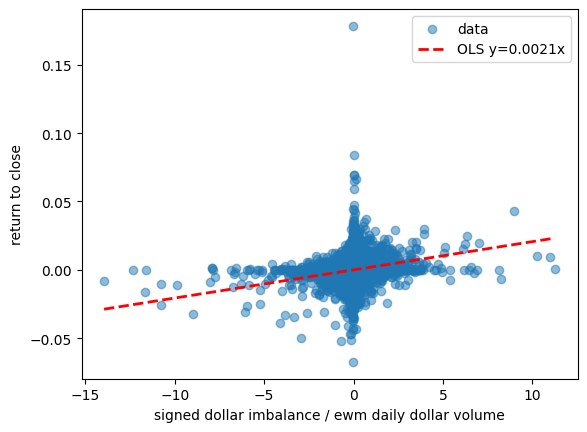

In [5]:
xs = np.linspace(np.min(X), np.max(X)).clip()
plt.scatter(X, y, alpha=0.5, label="data")
plt.plot(xs, res.params[0] * xs, label=f'OLS y={res.params[0]:,.4f}x', color='red', linestyle='--', linewidth=2)
plt.xlabel("signed dollar imbalance / ewm daily dollar volume")
plt.ylabel("return to close")
plt.legend()
plt.show()

In [6]:
from scipy.stats import spearmanr

ic, pval = spearmanr(X, y)
print(f"Spearman IC for ewm daily dollar volume: {ic:,.3f} with p-value: {pval:,.3f}")

Spearman IC for ewm daily dollar volume: 0.250 with p-value: 0.000


## Risk (Covariance) Model
Starting with a **SIMPLE** sample covariance of daily returns, filling null daily returns with the symbols **MEAN**.

Very much not a good enough covariance matrix yet. Need shrinkage or a factor model.

In [7]:
daily_ret = (
    df_trades
    .select(["ts_event", "symbol", "price"])
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"])
    .agg(
        pl.col("price").last()
    )
    .sort("date")
    .with_columns(
        pl.col("price").pct_change().over("symbol").alias("ret")
    )
    .pivot(
        on="symbol",
        on_columns=UNIVERSE,
        index="date",
        values="ret"
    )
    .with_columns(pl.all().exclude("date").fill_null(strategy="mean"))
    .with_columns(pl.all().exclude("date").fill_null(0.0))   # dead names (no trades all window) stay all-null after mean; zero them
)

daily_ret = daily_ret.collect(engine="streaming")
daily_ret

date,NVDA,SPY,TSLA,QQQ,AAPL,MSFT,AMZN,META,GOOGL,AVGO,AMD,TLT,GOOG,IWM,NFLX,TQQQ,MU,COST,ADBE,QCOM,COIN,SMCI,INTC,SMH,MSTR,TXN,AMAT,PEP,CSCO,BKNG,ASML,LRCX,TMUS,HYG,INTU,PDD,…,MMS,IGF,BITI,TNL,BANC,ASGN,OXM,ENOV,VSH,RLI,IDEV,BASE,LQDA,SCHR,VOE,ESNT,CHCO,PPH,LCII,AX,FNB,ESGD,SKYY,RITM,SHYG,TREE,AG,QQQE,ATGE,BKH,SPHY,FTSM,EFSC,TGNA,FIZZ,MAC,ANGL
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-11,0.001597,0.00078,0.001014,0.001115,0.001632,-0.000566,0.000619,-0.000532,0.002961,0.001955,0.006129,-0.000041,0.00289,0.001186,-0.004944,0.0011,0.009116,0.000015,-0.002046,0.001171,-0.000963,-0.000054,0.007623,0.003335,-0.003843,0.001691,0.004694,0.000513,0.002655,-0.005059,0.003522,0.005588,-0.000757,0.000002,-0.003545,-0.000716,…,-0.000343,0.000458,0.001798,0.001679,0.001498,-0.003261,0.000286,-0.001059,0.005564,-0.001102,0.000605,0.00382,0.006976,-0.000029,0.00074,0.000121,0.000421,0.000668,0.000255,0.001011,0.00114,0.000501,0.00068,-0.00077,-0.000038,0.000912,0.003615,0.000743,-0.00059,0.000995,-0.000029,-0.000003,0.000777,0.00118,-0.000699,0.001823,0.00002
2025-06-12,0.015051,0.003808,-0.022482,0.002273,0.00176,0.012963,0.000281,-0.001311,-0.009582,0.012214,-0.022521,0.012073,-0.010345,-0.003932,-0.004139,0.006515,0.001379,0.005366,0.003344,-0.005452,-0.038567,0.003588,0.003141,0.004927,-0.019038,-0.00005,0.0136,0.01793,0.014642,-0.000801,0.00172,0.007805,-0.010257,0.00088,0.001752,0.002617,…,0.008095,0.008599,0.018756,0.005601,-0.004248,-0.009918,-0.139519,-0.032103,0.002831,0.016885,0.00782,-0.006701,0.025168,0.002631,0.004793,0.011107,-0.002274,0.014485,-0.002813,0.005122,-0.006043,0.008041,0.002088,0.005265,0.001056,-0.033991,-0.010798,0.000623,-0.001375,-0.000174,0.000852,0.000334,-0.000748,-0.01008,-0.002942,-0.013243,0.002952
2025-06-13,-0.021,-0.011181,0.019615,-0.012592,-0.013755,-0.008496,-0.005299,-0.015084,-0.005805,-0.028819,-0.019495,-0.010151,-0.006215,-0.01828,-0.002255,-0.038705,-0.005249,-0.011692,-0.053514,-0.025142,0.006513,-0.04071,-0.029383,-0.023372,0.008137,-0.023386,-0.025808,-0.010735,-0.015659,-0.029931,-0.03193,-0.023451,-0.002973,-0.00289,-0.015935,-0.027652,…,-0.017188,-0.006687,0.015889,-0.049229,-0.030928,-0.02457,-0.083333,-0.011004,-0.048934,-0.018353,-0.011345,-0.010898,-0.025934,-0.002018,-0.011803,-0.009802,-0.012834,-0.010899,-0.026217,-0.035808,-0.026109,-0.013184,-0.017345,-0.014841,-0.002228,-0.029796,0.010916,-0.01412,0.017443,-0.011306,-0.002555,0.0,-0.022174,-0.015274,-0.019891,-0.01779,-0.003463
2025-06-16,0.019126,0.009649,0.011401,0.013873,0.009722,0.008801,0.019094,0.027877,0.011849,0.013671,0.087967,-0.009386,0.011883,0.008808,0.010922,0.041363,0.036589,-0.006399,0.024621,0.014091,0.078803,0.050252,0.028784,0.025683,-0.001463,0.021793,0.034873,0.004203,0.021522,0.013045,0.018515,0.043226,0.012674,0.002268,0.018633,0.022472,…,-0.004444,-0.017503,-0.033764,0.029916,-0.010271,0.005813,0.060268,0.010813,0.038259,-0.003082,-0.012992,0.004722,0.000355,-0.001618,0.007983,0.008022,-0.012145,-0.007713,0.02715,0.002214,0.010283,-0.013809,0.016786,0.000886,0.001763,0.034805,-0.006599,0.013269,0.012058,-0.010732,0.002561,0.000334,-0.006985,0.020377,-0.002007,0.021608,0.002606
2025-06-17,-0.004389,-0.008561,-0.038983,-0.009827,-0.013762,-0.002296,-0.006245,-0.006809,-0.004695,-0.010988,0.00538,0.012107,-0.00427,-0.010629,-0.003558,-0.029955,0.004256,-0.006725,-0.047262,-0.015425,-0.02999,-0.013278,0.002894,-0.00774,-0.018441,-0.007879,-0.013989,-0.016133,-0.002443,-0.012415,-0.019649,-0.007816,-0.041315,-0.001069,-0.004349,-0.002917,…,-0.003312,-0.008822,0.03777,-0.009141,-0.012602,-0.018301,0.012897,-0.042171,-0.026366,-0.009136,-0.011626,0.02376,-0.036906,0.002836,-0.008166,-0.018794,0.002684,-0.020544,-0.022008,-0.00563,-0.008361,-0.013775,

In [8]:
cov_matrix = np.cov(daily_ret.drop("date").to_numpy(), rowvar=False)
cov_matrix

array([[ 4.87374737e-04,  1.08337734e-04,  2.17920786e-04, ...,
        -4.05304978e-05,  2.60464642e-05,  2.15133778e-05],
       [ 1.08337734e-04,  5.88443095e-05,  1.18362497e-04, ...,
         8.82643847e-06,  5.87907286e-05,  1.58096328e-05],
       [ 2.17920786e-04,  1.18362497e-04,  7.81699100e-04, ...,
        -6.21466576e-05,  8.50203821e-05,  3.24399312e-05],
       ...,
       [-4.05304978e-05,  8.82643847e-06, -6.21466576e-05, ...,
         2.94850429e-04,  9.84989973e-05,  6.67196196e-06],
       [ 2.60464642e-05,  5.87907286e-05,  8.50203821e-05, ...,
         9.84989973e-05,  3.69923949e-04,  2.69338534e-05],
       [ 2.15133778e-05,  1.58096328e-05,  3.24399312e-05, ...,
         6.67196196e-06,  2.69338534e-05,  8.52961779e-06]],
      shape=(2000, 2000))

## Daily MVO Optimizer

In [9]:
import cvxpy as cp

class ForecastModel:
    """Maps a day's features -> dense alpha vector aligned to `universe`. Missing names -> 0."""
    def __init__(self, universe, beta_1):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}
        self.beta_1 = beta_1
    
    def get_alpha(self, day_df: pl.DataFrame) -> np.ndarray:
        """Gets the forecast mean return using beta_1. Does not include an intercept, so that 0 signal gets 0 forecast."""
        alpha = np.zeros(len(self.universe))
        for symbol, signal in zip(day_df['symbol'], day_df["signed_mean_imb_ratio"]):
            alpha[self.sym_idx_map[symbol]] = self.beta_1 * signal
        return alpha

class CostModel:
    """Half-spread (in return space) per name; names with no quote -> large cost so the optimizer avoids them."""
    def __init__(self, universe: list, commission: float):
        self.universe = universe
        self.commission = commission
        self.sym_idx_map = {s:i for i, s in enumerate(universe)}
    
    def get_cost(self, day_df: pl.DataFrame) -> np.ndarray:
        cost = np.zeros(len(self.universe))
        for symbol, spread in zip(day_df["symbol"], day_df["spread_return"]):
            cost[self.sym_idx_map[symbol]] = spread * 0.5 + self.commission
        return cost

class Optimizer:
    """Single-Period Daily MVO system."""
    def __init__(self, universe: list):
        self.universe = universe
        self.N = len(universe)
        
    def set_problem(self, Sigma: np.ndarray, lam: float):
        self.w = cp.Variable(self.N)
        self.alpha = cp.Parameter(self.N)
        self.cost = cp.Parameter(self.N, nonneg=True)
        self.Sigma = cp.psd_wrap(cp.Constant(Sigma))

        self.objective = cp.Maximize(
            self.alpha @ self.w
            - (lam/2) * cp.quad_form(self.w, self.Sigma)
            - (self.cost/2) @ cp.abs(self.w)
        )
        self.constraints = [
            cp.abs(cp.sum(self.w)) <= 1e-4,
            cp.norm(self.w, 1) <= 1,         # This is a no-leveraging constaint, because we have sample covariance right now. Otherwise it would blow up weights wiht 0 variance.
            cp.abs(self.w) <= 0.25
        ]
        self.problem = cp.Problem(self.objective, self.constraints)
    
    def solve(self, alpha, cost) -> np.ndarray:
        self.alpha.value = alpha
        self.cost.value = cost
        self.problem.solve(warm_start=True)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        return self.w.value

In [10]:
opt = Optimizer(UNIVERSE)
opt.set_problem(Sigma=cov_matrix, lam=1)
f_model = ForecastModel(UNIVERSE, beta_1 = res.params[0])
c_model = CostModel(UNIVERSE, commission=0.0035)

# weights = {}
# for d in data["date"].to_list():
#     day_df = data.filter(pl.col("date") == d)

#     alpha = f_model.get_alpha(day_df)
#     cost = c_model.get_cost(day_df)
#     ws = opt.solve(alpha, cost)
#     weights[d] = {s:w for s,w in zip(SYMBOLS, ws)}

## Parallel daily solve

Each trading day is an independent QP (the book is flat at every close), so the days fan out across processes with `joblib`'s `loky` backend (works with notebook-defined classes via cloudpickle). Each worker compiles the parametrized problem **once** and warm-starts through a contiguous chunk of days — so compile cost is paid `N_JOBS` times, not once per day. Produces `weights` in the same `{date: {symbol: w}}` shape as the serial loop, so the over-time plot above works unchanged: run this cell, then re-run the plot.

In [11]:
# --- Parallel daily solve (days are independent; book is flat at every close) ---
# Fans the days across processes. Each worker compiles the parametrized QP ONCE
# and warm-starts through a contiguous chunk of days. Produces `weights` in the
# same {date: {symbol: w}} shape as the serial loop, so the over-time plot works
# unchanged. Run AFTER f_model / c_model / SYMBOLS / cov_matrix are defined.
import os
from joblib import Parallel, delayed

N_JOBS = max(1, os.cpu_count() - 2)
LAM = 0.25

def _solve_chunk(symbols, Sigma, lam, day_records):
    """One worker: compile the QP once, then warm-start through its chunk of days."""
    opt = Optimizer(symbols)
    opt.set_problem(Sigma=Sigma, lam=lam)        # compile paid once per worker, not per day
    return [(date, opt.solve(alpha, cost)) for date, alpha, cost in day_records]

def _split_contiguous(items, n):
    """Contiguous chunks so adjacent days share a worker -> warm_start actually helps."""
    k, m = divmod(len(items), n)
    return [items[i * k + min(i, m):(i + 1) * k + min(i + 1, m)] for i in range(n)]

# Build per-day (alpha, cost) in the parent (cheap, vectorized) so workers receive
# only small 1-D arrays; cov_matrix is auto-memmapped by loky and shared read-only.
all_dates = data["date"].unique().sort().to_list()
day_records = [
    (d, f_model.get_alpha(day), c_model.get_cost(day))
    for d in all_dates
    for day in [data.filter(pl.col("date") == d)]
]

chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(_solve_chunk)(UNIVERSE, cov_matrix, LAM, chunk) for chunk in chunks
)

weights = {d: dict(zip(UNIVERSE, ws)) for chunk in chunk_results for d, ws in chunk}
print(f"solved {len(weights)} days across {len(chunks)} workers")

solved 248 days across 12 workers


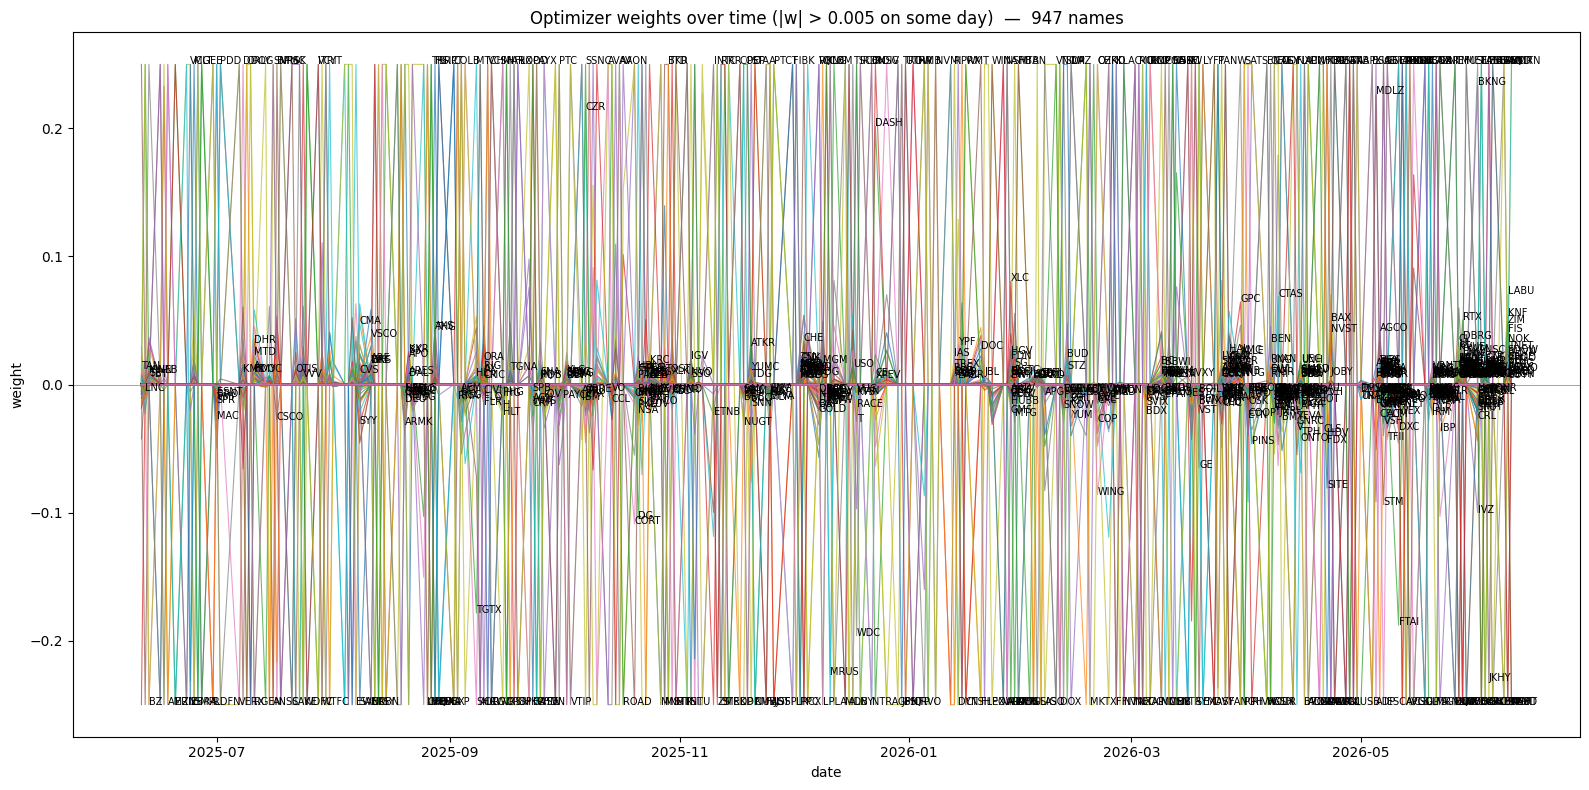

In [12]:
# Optimizer weights over time, one line per symbol (only names ever held)
dates = sorted(weights.keys())
label_thresh = 0.005  # a symbol is "held" if |weight| exceeds this on some day

held = sorted({s for d in dates for s, wv in weights[d].items() if abs(wv) > label_thresh})

fig, ax = plt.subplots(figsize=(16, 8))
for s in held:
    series = [weights[d].get(s, 0.0) for d in dates]
    ax.plot(dates, series, lw=0.8, alpha=0.7)
    # label at the symbol's last meaningful point
    last_idx = max(i for i, v in enumerate(series) if abs(v) > label_thresh)
    ax.annotate(s, (dates[last_idx], series[last_idx]), fontsize=7)

ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.set_title(f"Optimizer weights over time (|w| > {label_thresh} on some day)  —  {len(held)} names")
fig.tight_layout()
plt.show()

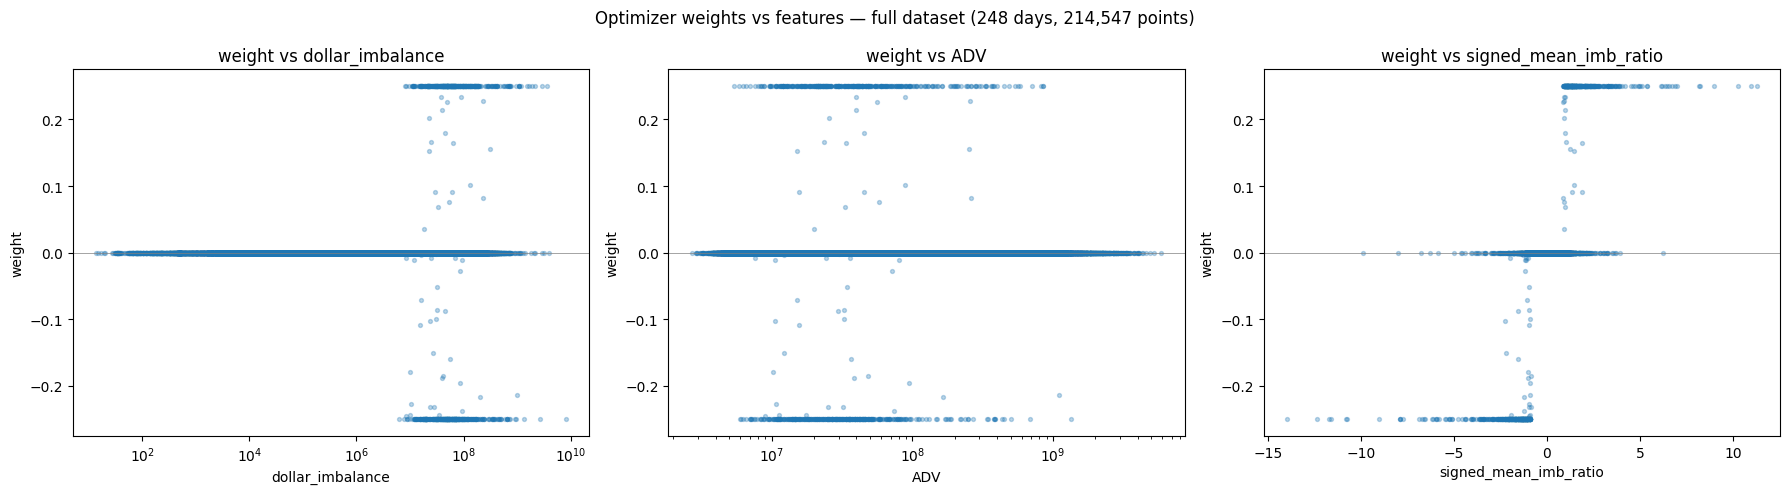

In [13]:
# Scatter weights vs day features over the FULL dataset (all dates pooled)
# Flatten {date: {symbol: w}} -> long frame, then join each day's features from `data`.
w_long = pl.DataFrame(
    {
        "date": [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

plot_df = data.join(w_long, on=["date", "symbol"], how="inner")

weights_arr = plot_df["weight"].to_numpy()
features = ["dollar_imbalance", "ADV", "signed_mean_imb_ratio"]
log_x = {"dollar_imbalance", "ADV"}   # positive, span orders of magnitude; signed ratio stays linear

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, features):
    x = plot_df[feat].to_numpy()
    ax.scatter(x, weights_arr, alpha=0.3, s=8)
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        ax.set_xscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("weight")
    ax.set_title(f"weight vs {feat}")

fig.suptitle(f"Optimizer weights vs features — full dataset ({len(weights)} days, {len(plot_df):,} points)")
fig.tight_layout()
plt.show()

## Accountant

Turns the optimizer `weights` (`{date: {symbol: w}}`) into a trade ledger and PnL/risk report.

- **Capital:** `CAPITAL` is deployed each day; weights are read as **dollar fractions**, so name *i*'s position is `w_i · CAPITAL` (gross `||w||₁·CAPITAL ≤ CAPITAL`).
- **Execution:** enter at 15:50 (`entry_price`), exit in the **closing auction** (`auction_price`).
- **Costs:** pay **half the quoted spread on entry only** (we cross once getting in; the auction print has no spread), and **commission both ways** (`COMMISSION_PER_SHARE` per share on each leg).
- **Output:** `trades` (per name/day) → `daily` (per-day PnL, equity, drawdown) → Sharpe, max drawdown, hit rate, and the equity curve.

In [14]:
# ----- Accountant inputs -----
CAPITAL = 1_000_000            # equity base each day; weights are dollar fractions (||w||_1 <= 1)
LEVERAGE = 2.0                 # gross target multiple: dollar_pos = weight*CAPITAL*LEVERAGE -> gross <= LEVERAGE*CAPITAL
ANNUAL_INTEREST_RATE = 0.05    # financing rate on borrowed funds (gross beyond CAPITAL); charged per day = rate/252
COMMISSION_PER_SHARE = 0.0035  # $/share, charged on BOTH entry and exit (round trip)
MIN_WEIGHT = 0              # ignore optimizer "dust" weights

# Flatten {date: {symbol: w}} -> long, then join the day's execution prices/spread from `data`.
w_long = pl.DataFrame(
    {
        "date":   [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

# Entry @ 15:50 (entry_price), exit @ closing auction (auction_price).
# Costs: half the quoted spread on ENTRY only; commission per share on BOTH legs.
# Positions are scaled by LEVERAGE; the financing cost of that leverage is charged per-day
# in the accountant cell (interest on gross exposure beyond CAPITAL).
trades = (
    data
    .join(w_long, on=["date", "symbol"], how="inner")
    .filter(pl.col("weight").abs() > MIN_WEIGHT)
    .with_columns(
        (pl.col("weight") * CAPITAL * LEVERAGE).alias("dollar_pos"),        # signed $ position
        (pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("asset_ret"),
    )
    .with_columns((pl.col("dollar_pos") // pl.col("entry_price")).alias("shares"))  # signed
    .with_columns(
        (pl.col("dollar_pos") * pl.col("asset_ret")).alias("gross_pnl"),
        (pl.col("dollar_pos").abs() * pl.col("spread_return").clip(lower_bound=0.0) / 2.0).alias("spread_cost"),
        (pl.col("shares").abs() * COMMISSION_PER_SHARE * 2.0).alias("commission_cost"),
    )
    .with_columns(
        (pl.col("gross_pnl") - pl.col("spread_cost") - pl.col("commission_cost")).alias("net_pnl")
    )
    .select([
        "date", "symbol", "side", "weight", "dollar_pos", "shares",
        "entry_price", "auction_price", "asset_ret",
        "gross_pnl", "spread_cost", "commission_cost", "net_pnl",
    ])
    .sort(["date", "symbol"])
)
trades

date,symbol,side,weight,dollar_pos,shares,entry_price,auction_price,asset_ret,gross_pnl,spread_cost,commission_cost,net_pnl
date,cat,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-11,"""AAL""","""A""",1.8928e-8,0.037856,0.0,11.035,11.06,0.002266,0.000086,0.000017,0.0,0.000069
2025-06-11,"""AAOI""","""B""",-5.2129e-9,-0.010426,-1.0,16.37,16.32,-0.003054,0.000032,0.000006,0.007,-0.006975
2025-06-11,"""AAON""","""B""",1.5511e-8,0.031022,0.0,75.78,75.85,0.000924,0.000029,0.000016,0.0,0.000012
2025-06-11,"""AAPL""","""A""",1.3387e-8,0.026774,0.0,198.81,198.78,-0.000151,-0.000004,0.000003,0.0,-0.000007
2025-06-11,"""AAXJ""","""N""",2.1121e-8,0.042242,0.0,81.8,81.88,0.000978,0.000041,0.000003,0.0,0.000039
…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""ZG""","""N""",3.1851e-8,0.063702,0.0,34.46,34.1,-0.010447,-0.000665,0.000009,0.0,-0.000675
2026-06-10,"""ZION""","""N""",2.3710e-8,0.047419,0.0,65.56,65.82,0.003966,0.000188,0.000007,0.0,0.000181
2026-06-10,"""ZLAB""","""A""",2.8666e-8,0.057331,0.0,17.3,17.26,-0.002312,-0.000133,0.000017,0.0,-0.000149


Leverage:           2x   (financing 5.0%/yr on gross beyond $1,000,000)
Days traded:        248
Capital / day:      $1,000,000   (avg gross exposure $1,591,328 = 1.59x)
Total net PnL:      $388,531
Cumulative return:  +38.85%
Ann. return:        +39.48%
Ann. volatility:    8.89%
Sharpe (ann):       4.44
Max drawdown:       -1.85%
CVaR 95% (daily):   -0.58%   (ann -9.18%)
CDaR 95%:           -1.39%
Daily hit rate:     56.5%
Total commission:   $31,669
Total spread cost:  $81,473
Total interest:     $31,154
SPY buy&hold:       +18.80%   (Sharpe 1.49)


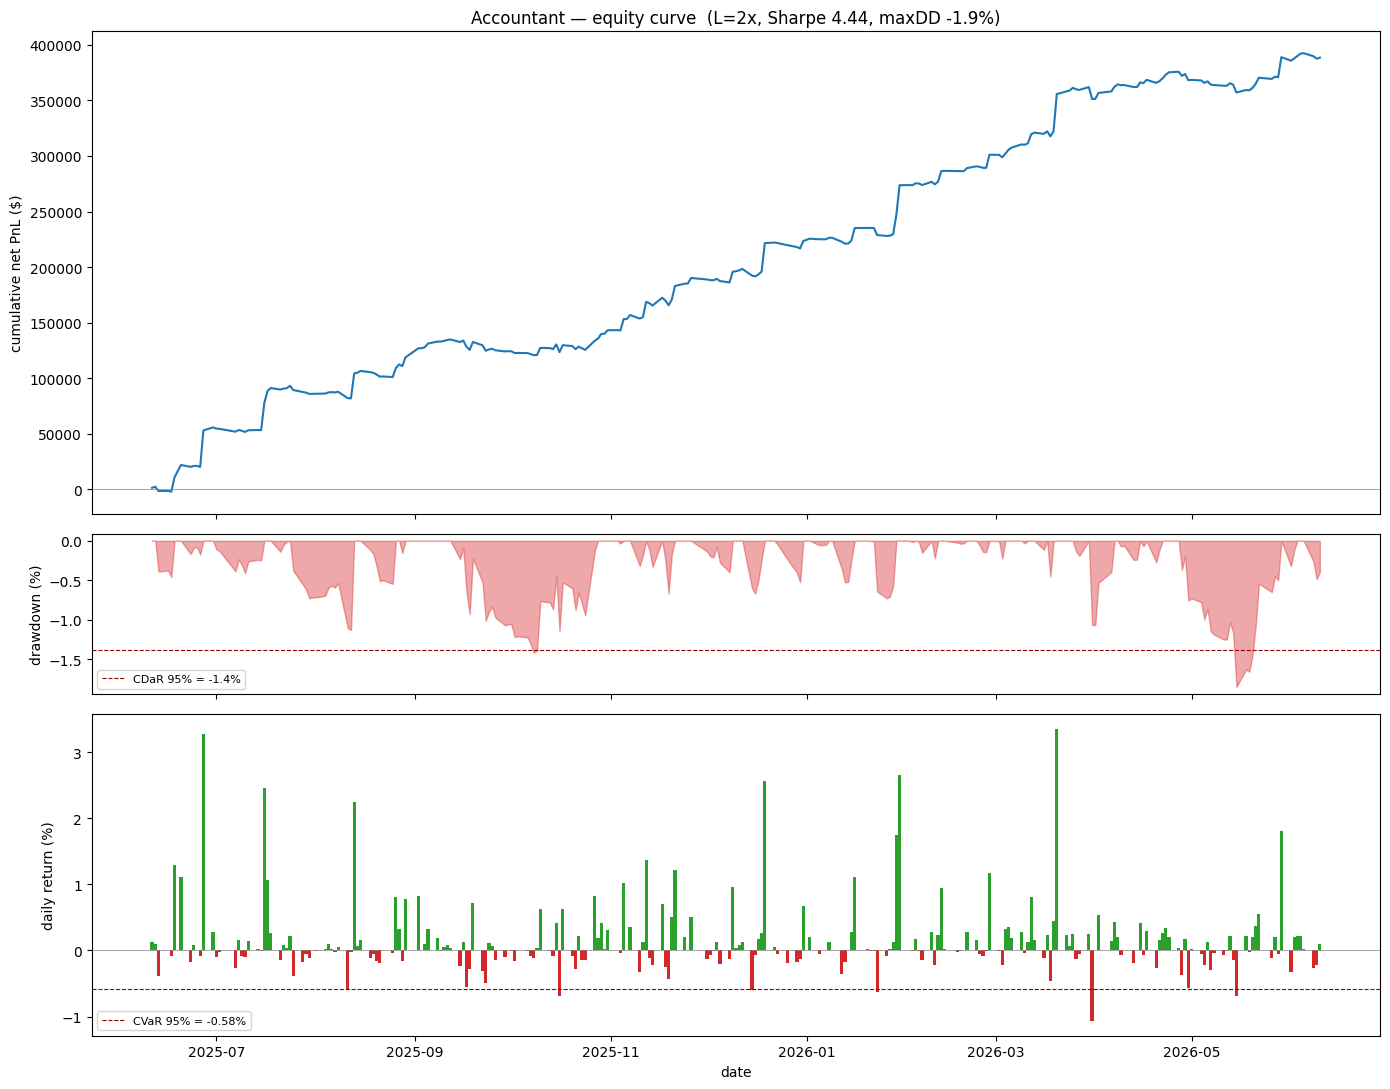

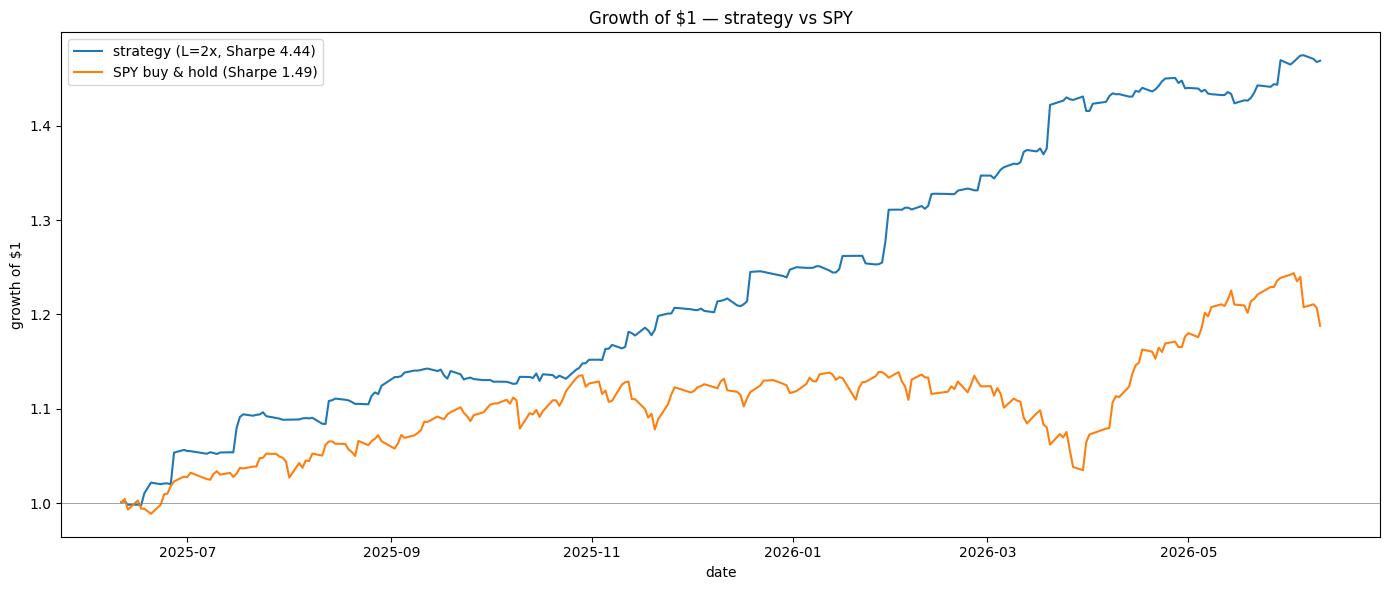

date,gross_pnl,spread_cost,commission_cost,trade_net_pnl,gross_exposure,n_positions,interest_cost,net_pnl,ret,cum_pnl,equity,drawdown,spy_ret,spy_equity
date,f64,f64,f64,f64,f64,u64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-11,1557.82139,238.221158,40.607,1278.993232,1.0000e6,891,0.007395,1278.985836,0.001279,1278.985836,1.001279,0.0,0.00078,1.00078
2025-06-12,1450.824304,197.516102,104.139,1149.169201,1.5001e6,910,99.216427,1049.952775,0.00105,2328.938611,1.00233,0.0,0.003808,1.00459
2025-06-13,-3304.431886,202.015752,287.091,-3793.538638,1.5001e6,920,99.228116,-3892.766754,-0.003893,-1563.828143,0.998428,-0.003893,-0.011181,0.993358
2025-06-16,784.608927,407.263707,57.995,319.35022,2.0001e6,900,198.426764,120.923456,0.000121,-1442.904687,0.998549,-0.003772,0.009649,1.002943
2025-06-17,-216.743078,267.502048,121.331,-605.576126,1.9754e6,904,193.52343,-799.099555,-0.000799,-2242.004242,0.997751,-0.004568,-0.008561,0.994356
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-04,3237.252664,641.722942,149.982,2445.547722,1.9647e6,851,191.409497,2254.138225,0.002254,392210.720818,1.47417,0.0,0.003766,1.239791
2026-06-05,913.519916,333.836474,136.101,443.582441,2.0000e6,858,198.404523,245.177918,0.000245,392455.898736,1.474531,0.0,-0.025891,1.207692
2026-06-08,-1351.232466,1014.09761,85.435,-2450.765076,2.0001e6,848,198.424497,-2649.189574,-0.002649,389806.709162,1.470625,-0.002649,0.002549,1.21077


In [17]:
# Daily PnL, equity curve, and risk/return metrics
ANN = 252  # trading days for annualization

daily = (
    trades
    .group_by("date")
    .agg(
        pl.col("gross_pnl").sum(),
        pl.col("spread_cost").sum(),
        pl.col("commission_cost").sum(),
        pl.col("net_pnl").sum().alias("trade_net_pnl"),         # net of spread+commission, BEFORE financing
        pl.col("dollar_pos").abs().sum().alias("gross_exposure"),
        pl.len().alias("n_positions"),
    )
    .sort("date")
    # Financing: interest on the borrowed portion = gross exposure beyond equity (CAPITAL),
    # charged at ANNUAL_INTEREST_RATE / 252 per day. LEVERAGE=1 -> no borrow -> no interest.
    .with_columns(
        ((pl.col("gross_exposure") - CAPITAL).clip(lower_bound=0.0) * (ANNUAL_INTEREST_RATE / ANN)).alias("interest_cost")
    )
    .with_columns((pl.col("trade_net_pnl") - pl.col("interest_cost")).alias("net_pnl"))
    .with_columns((pl.col("net_pnl") / CAPITAL).alias("ret"))   # return on the equity base (CAPITAL)
    .with_columns(
        pl.col("net_pnl").cum_sum().alias("cum_pnl"),
        (1.0 + pl.col("ret")).cum_prod().alias("equity"),       # strategy growth of $1 (compounded)
    )
    .with_columns((pl.col("equity") / pl.col("equity").cum_max() - 1.0).alias("drawdown"))
)

# SPY buy-and-hold benchmark for the growth-of-$1 comparison: SPY daily returns from
# `daily_ret` (covariance cell), aligned to `daily`'s dates and compounded from day 1.
daily = (
    daily
    .join(daily_ret.select(["date", "SPY"]).rename({"SPY": "spy_ret"}), on="date", how="left")
    .with_columns(pl.col("spy_ret").fill_null(0.0))
    .with_columns((1.0 + pl.col("spy_ret")).cum_prod().alias("spy_equity"))   # SPY growth of $1
)

# --- summary metrics ---
rets = daily["ret"].to_numpy()
sharpe   = rets.mean() / rets.std(ddof=1) * np.sqrt(ANN)
ann_ret  = rets.mean() * ANN
ann_vol  = rets.std(ddof=1) * np.sqrt(ANN)
total_pnl = daily["net_pnl"].sum()
# cum_ret  = daily["equity"][-1] - 1.0
cum_ret = total_pnl / CAPITAL
max_dd   = daily["drawdown"].min()
hit_rate = float((rets > 0).mean())

# Tail risk at the TAIL_ALPHA confidence level (mean of the worst (1-alpha) tail).
# CVaR = expected shortfall of daily returns: the average return on the worst tail of days.
# CDaR = conditional drawdown at risk: the average of the worst tail of the drawdown path.
# Both are reported as the daily figure; CVaR is also annualized (* sqrt(ANN)) for scale.
TAIL_ALPHA = 0.95
ret_var  = np.quantile(rets, 1.0 - TAIL_ALPHA)                  # VaR threshold (a daily loss, <= 0)
ret_tail = rets[rets <= ret_var]
cvar     = ret_tail.mean() if ret_tail.size else ret_var        # daily CVaR / expected shortfall (<= 0)
cvar_ann = cvar * np.sqrt(ANN)

dd       = daily["drawdown"].to_numpy()                         # drawdown path (<= 0)
dd_var   = np.quantile(dd, 1.0 - TAIL_ALPHA)                    # worst-tail drawdown threshold
dd_tail  = dd[dd <= dd_var]
cdar     = dd_tail.mean() if dd_tail.size else dd_var           # CDaR (<= 0)

spy_rets   = daily["spy_ret"].to_numpy()
spy_sharpe = spy_rets.mean() / spy_rets.std(ddof=1) * np.sqrt(ANN)
spy_cum_ret = daily["spy_equity"][-1] - 1.0

print(f"Leverage:           {LEVERAGE:g}x   (financing {ANNUAL_INTEREST_RATE:.1%}/yr on gross beyond ${CAPITAL:,.0f})")
print(f"Days traded:        {len(daily)}")
print(f"Capital / day:      ${CAPITAL:,.0f}   (avg gross exposure ${daily['gross_exposure'].mean():,.0f} = {daily['gross_exposure'].mean()/CAPITAL:.2f}x)")
print(f"Total net PnL:      ${total_pnl:,.0f}")
print(f"Cumulative return:  {cum_ret:+.2%}")
print(f"Ann. return:        {ann_ret:+.2%}")
print(f"Ann. volatility:    {ann_vol:.2%}")
print(f"Sharpe (ann):       {sharpe:.2f}")
print(f"Max drawdown:       {max_dd:.2%}")
print(f"CVaR {TAIL_ALPHA:.0%} (daily):   {cvar:.2%}   (ann {cvar_ann:.2%})")
print(f"CDaR {TAIL_ALPHA:.0%}:           {cdar:.2%}")
print(f"Daily hit rate:     {hit_rate:.1%}")
print(f"Total commission:   ${daily['commission_cost'].sum():,.0f}")
print(f"Total spread cost:  ${daily['spread_cost'].sum():,.0f}")
print(f"Total interest:     ${daily['interest_cost'].sum():,.0f}")
print(f"SPY buy&hold:       {spy_cum_ret:+.2%}   (Sharpe {spy_sharpe:.2f})")

# --- equity curve + drawdown + daily return bars (strategy only, in $) ---
dts = daily["date"].to_list()
bar_colors = np.where(rets >= 0, "tab:green", "tab:red")

fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1, figsize=(14, 11), sharex=True, height_ratios=[3, 1, 2]
)
ax1.plot(dts, daily["cum_pnl"].to_numpy(), color="tab:blue")
ax1.axhline(0, color="grey", lw=0.5)
ax1.set_ylabel("cumulative net PnL ($)")
ax1.set_title(f"Accountant — equity curve  (L={LEVERAGE:g}x, Sharpe {sharpe:.2f}, maxDD {max_dd:.1%})")

ax2.fill_between(dts, daily["drawdown"].to_numpy() * 100, 0, color="tab:red", alpha=0.4)
ax2.axhline(cdar * 100, color="darkred", lw=0.8, ls="--", label=f"CDaR {TAIL_ALPHA:.0%} = {cdar:.1%}")
ax2.set_ylabel("drawdown (%)")
ax2.legend(loc="lower left", fontsize=8)

ax3.bar(dts, rets * 100, color=bar_colors, width=1.0)
ax3.axhline(0, color="grey", lw=0.5)
ax3.axhline(cvar * 100, color="darkred", lw=0.8, ls="--", label=f"CVaR {TAIL_ALPHA:.0%} = {cvar:.2%}")
ax3.set_ylabel("daily return (%)")
ax3.set_xlabel("date")
ax3.legend(loc="lower left", fontsize=8)

fig.tight_layout()
plt.show()

# --- growth of $1: strategy vs SPY (risk-adjusted comparison on the same $1 base) ---
figg, axg = plt.subplots(figsize=(14, 6))
axg.plot(dts, daily["equity"].to_numpy(), color="tab:blue",
         label=f"strategy (L={LEVERAGE:g}x, Sharpe {sharpe:.2f})")
axg.plot(dts, daily["spy_equity"].to_numpy(), color="tab:orange",
         label=f"SPY buy & hold (Sharpe {spy_sharpe:.2f})")
axg.axhline(1.0, color="grey", lw=0.5)
axg.set_ylabel("growth of $1")
axg.set_xlabel("date")
axg.set_title("Growth of $1 — strategy vs SPY")
axg.legend(loc="upper left")
figg.tight_layout()
plt.show()

daily

#### Plotting GMV, sharpe, and returns vs different values of the lambda penalty

/Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


lam= 0.0   ann_ret=+21.53%   sharpe=  4.80   GMV= 0.80x
lam= 0.5   ann_ret=+20.94%   sharpe=  4.80   GMV= 0.79x


/Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


lam= 1.0   ann_ret=+20.81%   sharpe=  4.89   GMV= 0.77x
lam= 1.5   ann_ret=+20.83%   sharpe=  4.95   GMV= 0.77x
lam= 2.0   ann_ret=+20.61%   sharpe=  4.94   GMV= 0.76x
lam= 2.5   ann_ret=+20.35%   sharpe=  4.91   GMV= 0.75x
lam= 3.0   ann_ret=+20.16%   sharpe=  4.88   GMV= 0.74x
lam= 3.5   ann_ret=+20.05%   sharpe=  4.87   GMV= 0.73x
lam= 4.0   ann_ret=+19.92%   sharpe=  4.86   GMV= 0.73x
lam= 4.5   ann_ret=+19.79%   sharpe=  4.85   GMV= 0.72x
lam= 5.0   ann_ret=+19.65%   sharpe=  4.83   GMV= 0.71x


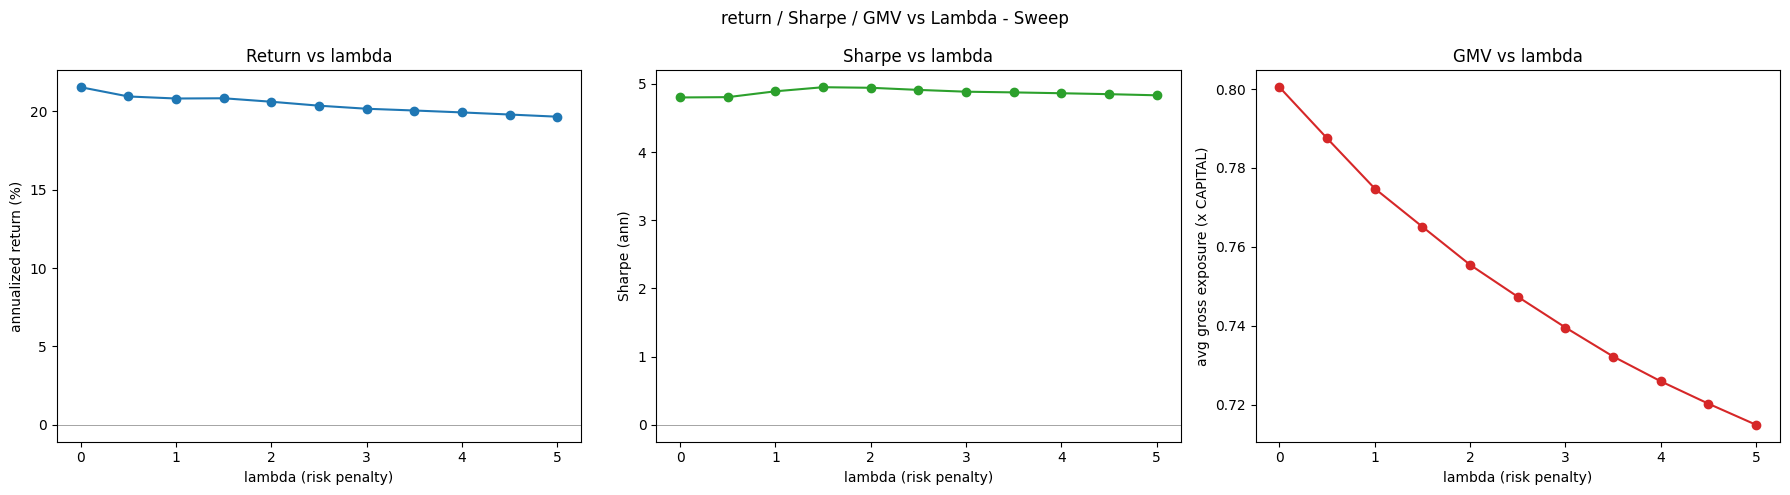

In [ ]:
# ===== Risk-aversion sweep: return / Sharpe / GMV vs lambda (1x leverage) =====
# Re-solve EVERY day across a grid of lambdas, then run the accountant at LEVERAGE=1x.
# alpha/cost are lambda-independent, so `day_records` / `chunks` are reused unchanged and
# only the QP solve repeats per lambda. Run AFTER the parallel-solve cell.

LAMBDAS = np.arange(0.0, 5.0 + 1e-9, 0.5)   # 0, 0.5, 1.0, ..., 5.0

# 1x-leverage accountant constants (financing is zero at 1x, so the interest leg drops out)
_CAPITAL = 1_000_000
_LEVERAGE = 1.0
_COMMISSION_PER_SHARE = 0.0035
_ANN = 252

def _metrics_for_weights(weights):
    """Accountant at LEVERAGE=1x -> (ann_return, ann_sharpe, avg gross exposure / CAPITAL)."""
    w_long = pl.DataFrame({
        "date":   [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }).with_columns(pl.col("symbol").cast(pl.Categorical))

    daily = (
        data
        .join(w_long, on=["date", "symbol"], how="inner")
        .with_columns(
            (pl.col("weight") * _CAPITAL * _LEVERAGE).alias("dollar_pos"),
            (pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("asset_ret"),
        )
        .with_columns((pl.col("dollar_pos") // pl.col("entry_price")).alias("shares"))
        .with_columns(
            (pl.col("dollar_pos") * pl.col("asset_ret")).alias("gross_pnl"),
            (pl.col("dollar_pos").abs() * pl.col("spread_return").clip(lower_bound=0.0) / 2.0).alias("spread_cost"),
            (pl.col("shares").abs() * _COMMISSION_PER_SHARE * 2.0).alias("commission_cost"),
        )
        .with_columns((pl.col("gross_pnl") - pl.col("spread_cost") - pl.col("commission_cost")).alias("net_pnl"))
        .group_by("date")
        .agg(
            pl.col("net_pnl").sum().alias("net_pnl"),               # 1x: no financing leg to subtract
            pl.col("dollar_pos").abs().sum().alias("gross_exposure"),
        )
        .sort("date")
        .with_columns((pl.col("net_pnl") / _CAPITAL).alias("ret"))
    )
    rets = daily["ret"].to_numpy()
    sharpe  = rets.mean() / rets.std(ddof=1) * np.sqrt(_ANN)
    ann_ret = rets.mean() * _ANN
    gmv     = daily["gross_exposure"].mean() / _CAPITAL            # avg gross exposure (multiple of CAPITAL)
    return ann_ret, sharpe, gmv

sweep = []
for lam in LAMBDAS:
    chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(_solve_chunk)(UNIVERSE, cov_matrix, float(lam), chunk) for chunk in chunks
    )
    weights_lam = {d: dict(zip(UNIVERSE, ws)) for chunk in chunk_results for d, ws in chunk}
    ann_ret, sharpe, gmv = _metrics_for_weights(weights_lam)
    sweep.append((float(lam), ann_ret, sharpe, gmv))
    print(f"lam={lam:4.1f}   ann_ret={ann_ret:+7.2%}   sharpe={sharpe:6.2f}   GMV={gmv:5.2f}x")

lams     = [r[0] for r in sweep]
ann_rets = [r[1] for r in sweep]
sharpes  = [r[2] for r in sweep]
gmvs     = [r[3] for r in sweep]

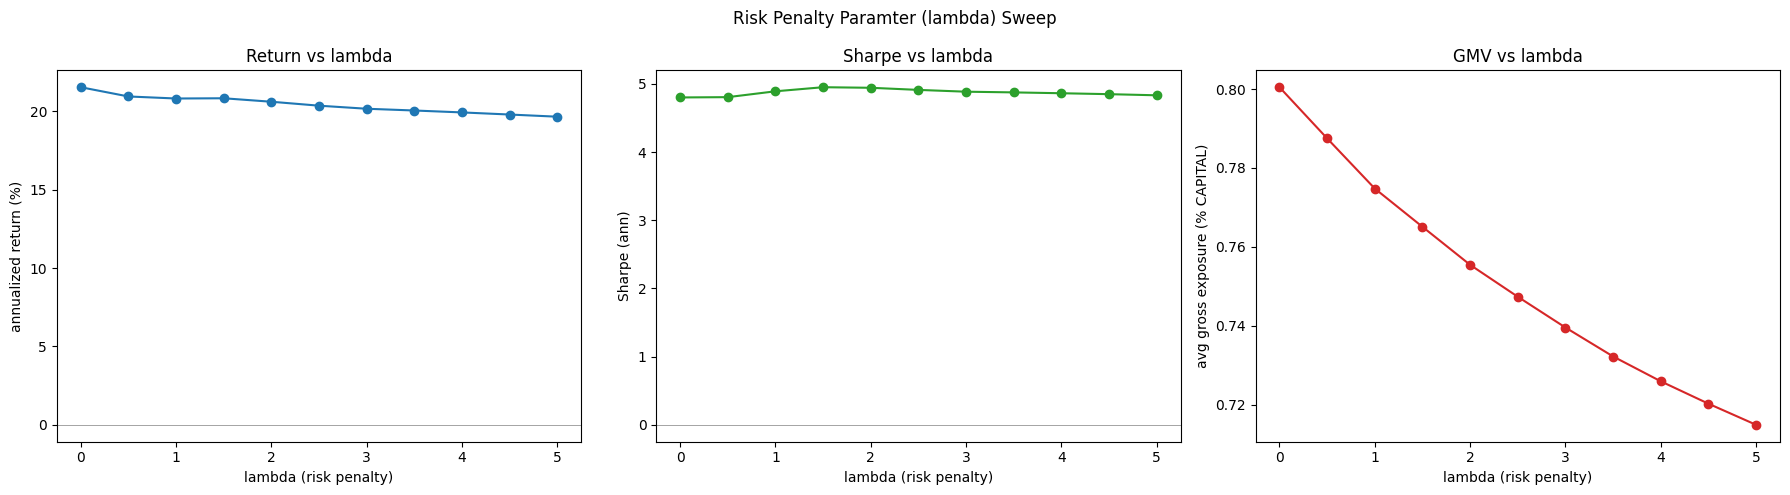

In [20]:
fig, (axr, axs, axg) = plt.subplots(1, 3, figsize=(18, 5))
axr.plot(lams, np.array(ann_rets) * 100, marker="o", color="tab:blue")
axr.axhline(0, color="grey", lw=0.5)
axr.set_xlabel("lambda (risk penalty)"); axr.set_ylabel("annualized return (%)")
axr.set_title("Return vs lambda")

axs.plot(lams, sharpes, marker="o", color="tab:green")
axs.axhline(0, color="grey", lw=0.5)
axs.set_xlabel("lambda (risk penalty)"); axs.set_ylabel("Sharpe (ann)")
axs.set_title("Sharpe vs lambda")

axg.plot(lams, gmvs, marker="o", color="tab:red")
axg.set_xlabel("lambda (risk penalty)"); axg.set_ylabel("avg gross exposure (% CAPITAL)")
axg.set_title("GMV vs lambda")

fig.suptitle("Risk Penalty Paramter (lambda) Sweep")
fig.tight_layout()
plt.show()
